In [2]:
%matplotlib inline
import cv2
import numpy as np
import pathlib
from matplotlib import pyplot as plt
import exiftool
from itertools import count
import ipywidgets as widgets
from IPython.display import display

In [3]:
### Data, paths
PROJ_ROOT = pathlib.Path.cwd().resolve().parent
DATA_RAW = PROJ_ROOT / 'data' / 'raw'
SCALE_FACTOR = 0.25
MAX_CORNER = 100
# ShiTomasi corner detection
config_st = {'maxCorners': MAX_CORNER,
             'qualityLevel': 0.3,
             'minDistance': 7,
             'blockSize': 7}
# Lucas-Kanade optical flow
config_lk = {'winSize': (15, 15),
             'maxLevel': 2,
             'criteria': (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)}
colors = np.random.randint(0, 255, (100, 3))

In [6]:


def pre_processing(frame: np.ndarray, scale_factor=SCALE_FACTOR, to_gray=True) -> np.ndarray:
    if to_gray:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)  # convert to gray
    frame = cv2.resize(frame, (int(frame.shape[1]*scale_factor), int(frame.shape[0]*scale_factor)), interpolation=cv2.INTER_AREA)# resize
    return frame


def get_intrinsic_matrix(frame: np.ndarray, focal_length: float, diag_35_mm: float = 43.27) -> np.ndarray:
    """
    returns: K - intrinsic camera matrix, 3x3
    """
    # assert len(frame.shape) == 2, 'gray image should be passed'
    f = float(focal_length * np.hypot(*frame.shape[:2]) / diag_35_mm)
    return np.array([
        [f, 0, frame.shape[1] // 2],
        [0, f, frame.shape[0] // 2],
        [0, 0, 1]
    ])


def get_metadata(file_path: str | pathlib.Path ):
    with exiftool.ExifToolHelper() as et:
        return et.get_metadata(str(file_path))[-1]


class FrameViewer:
    """Show frames in one matplotlib figure that updates in place, like cv2.imshow."""

    def __init__(self, title: str = 'lk_track', figsize=(10, 6)):
        self.fig, self.ax = plt.subplots(figsize=figsize)
        self.ax.axis('off')
        self.ax.set_title(title)
        self.artist = None
        self.handle = display(self.fig, display_id=True)
        plt.close(self.fig)  # keep the inline backend from rendering a duplicate copy

    def show(self, frame_bgr: np.ndarray, title: str | None = None) -> None:
        rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        if self.artist is None:
            self.artist = self.ax.imshow(rgb)
        else:
            self.artist.set_data(rgb)  # reuse the existing image instead of redrawing it
        if title:
            self.ax.set_title(title)
        self.handle.update(self.fig)




Image(value=b'', format='jpeg')

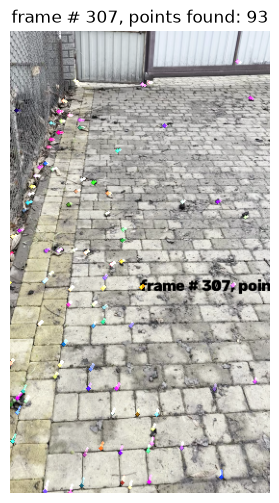

end of video


In [7]:
# v1:
# - add tracks
# - jitter compensation

file_path = DATA_RAW / 'straight.MOV'
video = cv2.VideoCapture(file_path)
_, first_frame = video.read()

previous = pre_processing(first_frame, to_gray=False)
focal_length  = get_metadata(file_path)['QuickTime:FocalLengthIn35mmFormat']
intrinsic = get_intrinsic_matrix(previous, focal_length)


previous_gray = cv2.cvtColor(previous, cv2.COLOR_BGR2GRAY)
p_src = cv2.goodFeaturesToTrack(previous_gray, mask=None, **config_st)

# to draw upon
stop_frame = 100
mask  = np.zeros_like(previous)
counter = count()
view = widgets.Image(format='jpeg')
display(view)
count_per_frame = []
matched_points = []
arrow_scaler = 4

viewer = FrameViewer('path_tracker')


while True:
    idx = next(counter)
    ok, target = video.read()
    if not ok:
        print('end of video')
        break

    target = pre_processing(target, to_gray=False)
    dst_gray = cv2.cvtColor(target, cv2.COLOR_BGR2GRAY)
    p_dst, status, err = cv2.calcOpticalFlowPyrLK(previous_gray, dst_gray, p_src.reshape(-1, 1, 2), None, **config_lk)
    # p_src, status, err = cv2.calcOpticalFlowPyrLK(dst_gray, previous_gray, p_src, None, **config_lk)
    if p_dst is None:
        p_src = cv2.goodFeaturesToTrack(dst_gray, mask=None, **config_st)
        previous_gray = np.copy(dst_gray)
        matched_points.append(None)
        continue

    p_dst = p_dst[status==1]
    p_src = p_src.reshape(-1, 1, 2)[status==1]
    
    if len(p_dst) < 15:
        p_src = cv2.goodFeaturesToTrack(dst_gray, mask=None, **config_st)
        previous_gray = np.copy(dst_gray)
        matched_points.append(None)
        continue
    
    # drawing tracks:
    matched_points.append((p_src, p_dst))

    for _id, (dst, src) in enumerate(zip(p_dst, p_src)):
        x_dst, y_dst = dst
        x_src, y_src = src

        mask = cv2.arrowedLine(mask, (int(x_src), int(y_src )), (int(x_dst), int(y_dst)), colors[_id].tolist(), 2)    
        # mask = cv2.line(mask, (int(x_src), int(y_src )), (int(x_dst), int(y_dst)), colors[_id].tolist(), 2)    
        target = cv2.circle(target, (int(x_dst), int(y_dst)), 2, colors[_id].tolist(), -1)
    target = cv2.putText(target, f'frame # {idx}, points found: {len(p_dst)}', (target.shape[1] // 2, target.shape[1],), cv2.FONT_HERSHEY_PLAIN, 1.0, (0, 0, 0), thickness = 2, lineType=cv2.LINE_AA)
    
    result = cv2.add(target, mask)
   

    # plt.subplot(111), plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB)), plt.title(f'frame # {idx}, points found: {len(p_dst)}')
    # plt.draw(), plt.show()
    # plt.waitforbuttonpress(1/25)
    # plt.clf()
    # cv2.imshow('lk_track', result)
    # ch = 0xFF & cv2.waitKey(1)
    # if ch == 27:
    #     break
    viewer.show(result, f'frame # {idx}, points found: {len(p_dst)}')

    #update previous frame and previous points:
    previous_gray = np.copy(dst_gray)
    p_src = p_dst

    # store found points
    count_per_frame.append(len(p_src))
    point_difference = MAX_CORNER - len(p_src)
    if point_difference > 0.1 * MAX_CORNER:
        known_points_mask = np.zeros_like(dst_gray)
        known_points_mask[:] = 255  # fill with white
        for x,y in p_src:
            cv2.circle(known_points_mask, (int(x), int(y)), 7, 0, -1)
        
        # enrich current with new features
        p = cv2.goodFeaturesToTrack(previous_gray, mask=known_points_mask, **{**config_st, 'maxCorners': point_difference})
        if p is not None:
            p_src = np.concatenate([p_src, p.reshape(-1, 2)])
    mask.fill(0)



    # if idx == stop_frame: break



    # select matched points


    

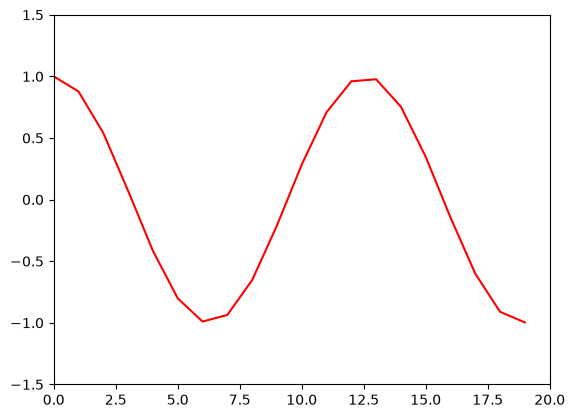

In [9]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

fig, ax = plt.subplots()
x_data, y_data = [], []

for i in range(20):
    x_data.append(i)
    y_data.append(np.cos(i * 0.5))
    
    ax.clear()
    ax.plot(x_data, y_data, 'r-')
    ax.set_xlim(0, 20)
    ax.set_ylim(-1.5, 1.5)
    
    # Clear the previous image and display the new frame
    clear_output(wait=True)
    display(fig)
    time.sleep(0.2)

# Prevent a duplicate static image from printing when the loop finishes
plt.close(fig)
